In [1]:
import mdtraj as md
import numpy as np
import matplotlib.pyplot as plt


nucls = ["AUUC", "CUUC", "UUUC", "GUUC", "ACUC", "AAUC", "AGUC", "AUCC", "AUAC", "AUGC", "AUUU", "AUUA", "AUUG"]
base_dirs = {nucl: f"../20251002_FUS-RRM_mut/20251002_FUS-RRM_mut-{nucl}" for nucl in nucls}
base_dirs["AUUC"] = "../20250801_FUS-RRM"

gleap_targets = {nucl: md.load(f"{base_dirs[nucl]}/2_md-preparation-2/gleap.target.gro") for nucl in nucls}
atom_indices_protein             = {nucl: gleap_targets[nucl].topology.select("resid 23 to 126") for nucl in nucls}
atom_indices_rna                 = {nucl: gleap_targets[nucl].topology.select("resid  0 to  22") for nucl in nucls}
atom_index_protein_min           = {nucl: min(atom_indices_protein[nucl])                        for nucl in nucls}


def calculate_interactions(xtc, atom_indices_protein, atom_indices_rna, atom_index_protein_min, gleap_target):
    for atom in gleap_target.topology.atoms:
        if atom.element.symbol == "VS":
            atom.element = md.element.get_by_symbol(atom.name[0])

    _interactions = np.zeros((len(atom_indices_protein), len(atom_indices_rna), xtc.n_frames))
    for timestep in range(xtc.n_frames):
        hbonds = md.baker_hubbard(xtc[timestep], distance_cutoff=0.25, angle_cutoff=120)

        for hbond in hbonds:
            # atom_index_donor    = hbond[0]
            atom_index_hydrogen = hbond[1]
            atom_index_acceptor = hbond[2]
            if atom_index_hydrogen in atom_indices_protein and atom_index_acceptor in atom_indices_rna:
                _interactions[atom_index_hydrogen-atom_index_protein_min, atom_index_acceptor, timestep] += 1
            elif atom_index_hydrogen in atom_indices_rna and atom_index_acceptor in atom_indices_protein:
                _interactions[atom_index_acceptor-atom_index_protein_min, atom_index_hydrogen, timestep] += 1

    nonzero_indices = _interactions.nonzero()
    return nonzero_indices, _interactions[nonzero_indices]


interactions_mut = {}
for i_nucl, nucl in enumerate(nucls):
    print(nucl)
    interactions_mut[nucl] = np.zeros((5, len(atom_indices_protein[nucl]), len(atom_indices_rna[nucl]), 1500))
    for trial in range(len(interactions_mut[nucl])):
        xtc = md.load(f"{base_dirs[nucl]}/6_cmd-{trial+1}/cmd.skip10.whole.target.pbc.xtc", top=gleap_targets[nucl])[5001::10]
        nonzero_indices, nonzero_vals = calculate_interactions(xtc, atom_indices_protein[nucl], atom_indices_rna[nucl], atom_index_protein_min[nucl], gleap_targets[nucl])
        interactions_mut[nucl][trial][nonzero_indices] = nonzero_vals

AUUC
CUUC
UUUC
GUUC
ACUC
AAUC
AGUC
AUCC
AUAC
AUGC
AUUU
AUUA
AUUG


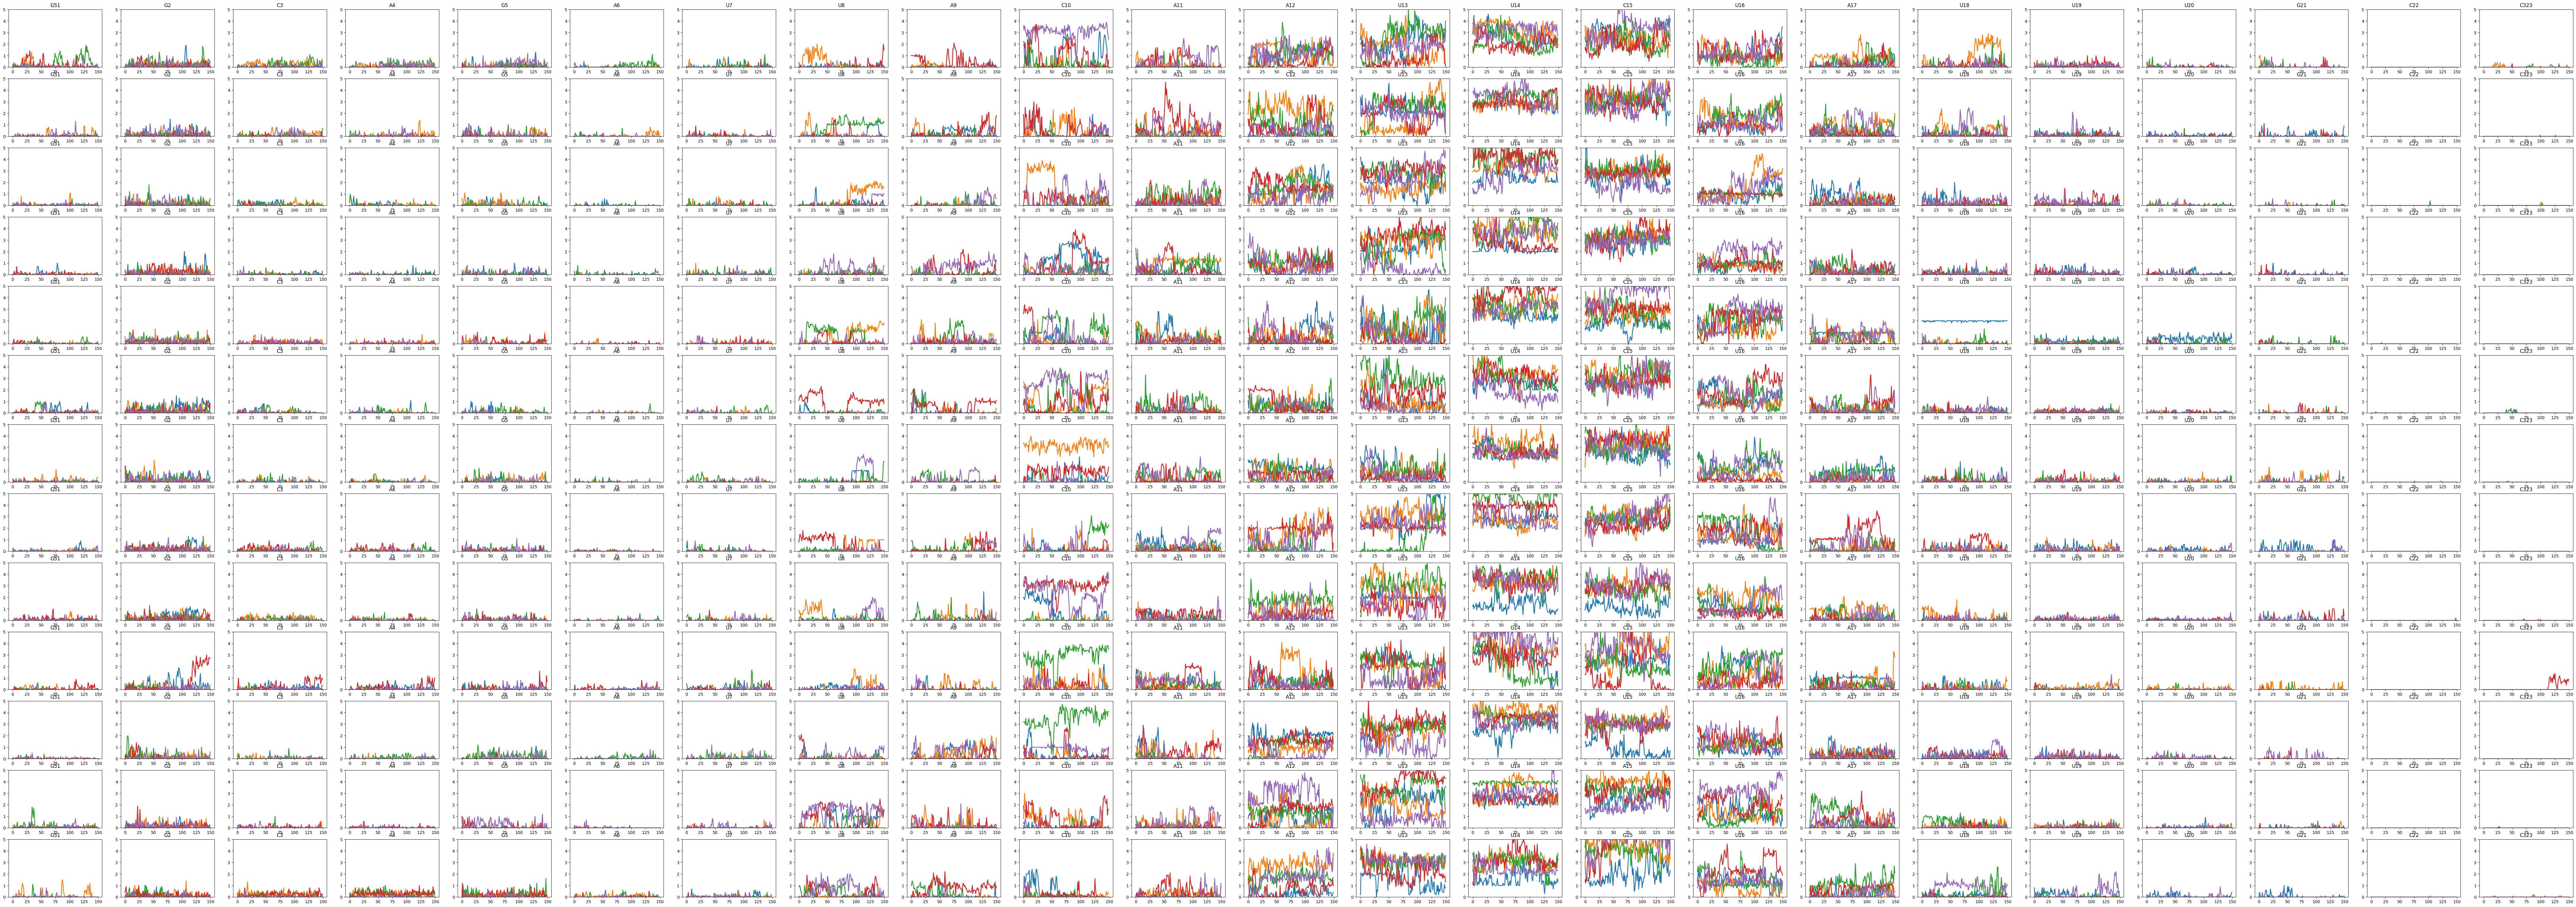

In [2]:
YMAX = 5

fig, ax = plt.subplots(len(nucls), 23)
fig.set_size_inches(112, 3*len(nucls))

for i_nucl, nucl in enumerate(nucls):
    for trial in range(len(interactions_mut[nucl])):
        for residue_index_rna in range(0, 23):
            atom_idices_rna_residue = gleap_targets[nucl].topology.select(f"resid {residue_index_rna}")
            atom_index_rna_resiude_min = min(atom_idices_rna_residue)
            atom_index_rna_resiude_max = max(atom_idices_rna_residue)
            
            interactions_sum = interactions_mut[nucl][trial, :, atom_index_rna_resiude_min:atom_index_rna_resiude_max+1, :].sum(axis=0).sum(axis=0).reshape(-1, 10).mean(axis=1)
    
            ax[i_nucl, residue_index_rna].plot(interactions_sum, linewidth=2)
            ax[i_nucl, residue_index_rna].set_title(gleap_targets[nucl].topology.residue(residue_index_rna))
            ax[i_nucl, residue_index_rna].set_ylim(0, YMAX)

In [3]:
def make_label_protein(atom):
    return f"{atom.residue.name}{atom.residue.index+252}-{atom.name}"


fractions = {nucl: interactions_mut[nucl].mean(axis=0).mean(axis=2) for nucl in nucls}

for nucl in nucls:
    print(nucl)
    for index_row, index_column in zip(*np.unravel_index(np.argsort(fractions[nucl], axis=None)[-30:][::-1], fractions[nucl].shape)):
        print(f"{make_label_protein(gleap_targets[nucl].topology.atom(index_row+atom_index_protein_min[nucl]))}={gleap_targets[nucl].topology.atom(index_column)}: {fractions[nucl][index_row, index_column]:.2f}")

AUUC
THR370-H=U14-O2: 0.99
THR370-O=U14-HO2': 0.68
ARG372-H=C15-OP2: 0.63
ALA369-O=C15-H42: 0.38
THR370-HG1=U14-O2': 0.37
ASN323-HD21=U16-OP2: 0.32
THR326-H=U13-O2: 0.29
THR326-OG1=U13-H3: 0.28
THR286-HG1=C15-O2: 0.25
ALA373-H=C15-OP2: 0.23
ARG377-HE=C10-O2: 0.22
ASN323-HD22=U16-OP2: 0.21
ARG377-HH11=C10-N3: 0.19
ARG372-HH21=C15-OP1: 0.19
ARG372-HE=C15-OP1: 0.18
LEU324-O=A12-H61: 0.16
THR326-H=U13-OP1: 0.14
ARG377-HH11=C10-O2: 0.13
NME378-H=C10-O2': 0.12
ARG371-HH11=A17-OP1: 0.11
ARG372-HH11=U14-OP1: 0.11
THR326-O=U13-H3: 0.10
ARG328-HH22=U13-OP2: 0.10
LYS334-HZ3=U14-OP2: 0.09
ASN323-HD21=U16-OP1: 0.08
ARG372-HE=C15-OP2: 0.08
ARG328-H=U13-O4: 0.08
ARG328-H=U13-O2: 0.08
THR286-HG1=C15-N3: 0.08
ARG328-HH21=A12-OP2: 0.07
CUUC
THR370-H=U14-O2: 0.99
THR370-O=U14-HO2': 0.97
ARG372-H=C15-OP2: 0.86
THR370-HG1=U14-O2': 0.47
ASN323-HD21=U16-OP2: 0.40
ALA369-O=C15-H42: 0.39
ALA373-H=C15-OP2: 0.38
THR326-O=U13-H3: 0.34
THR286-HG1=C15-O2: 0.32
ARG328-H=U13-O4: 0.28
THR326-H=U13-O2: 0.26
THR326-OG1=

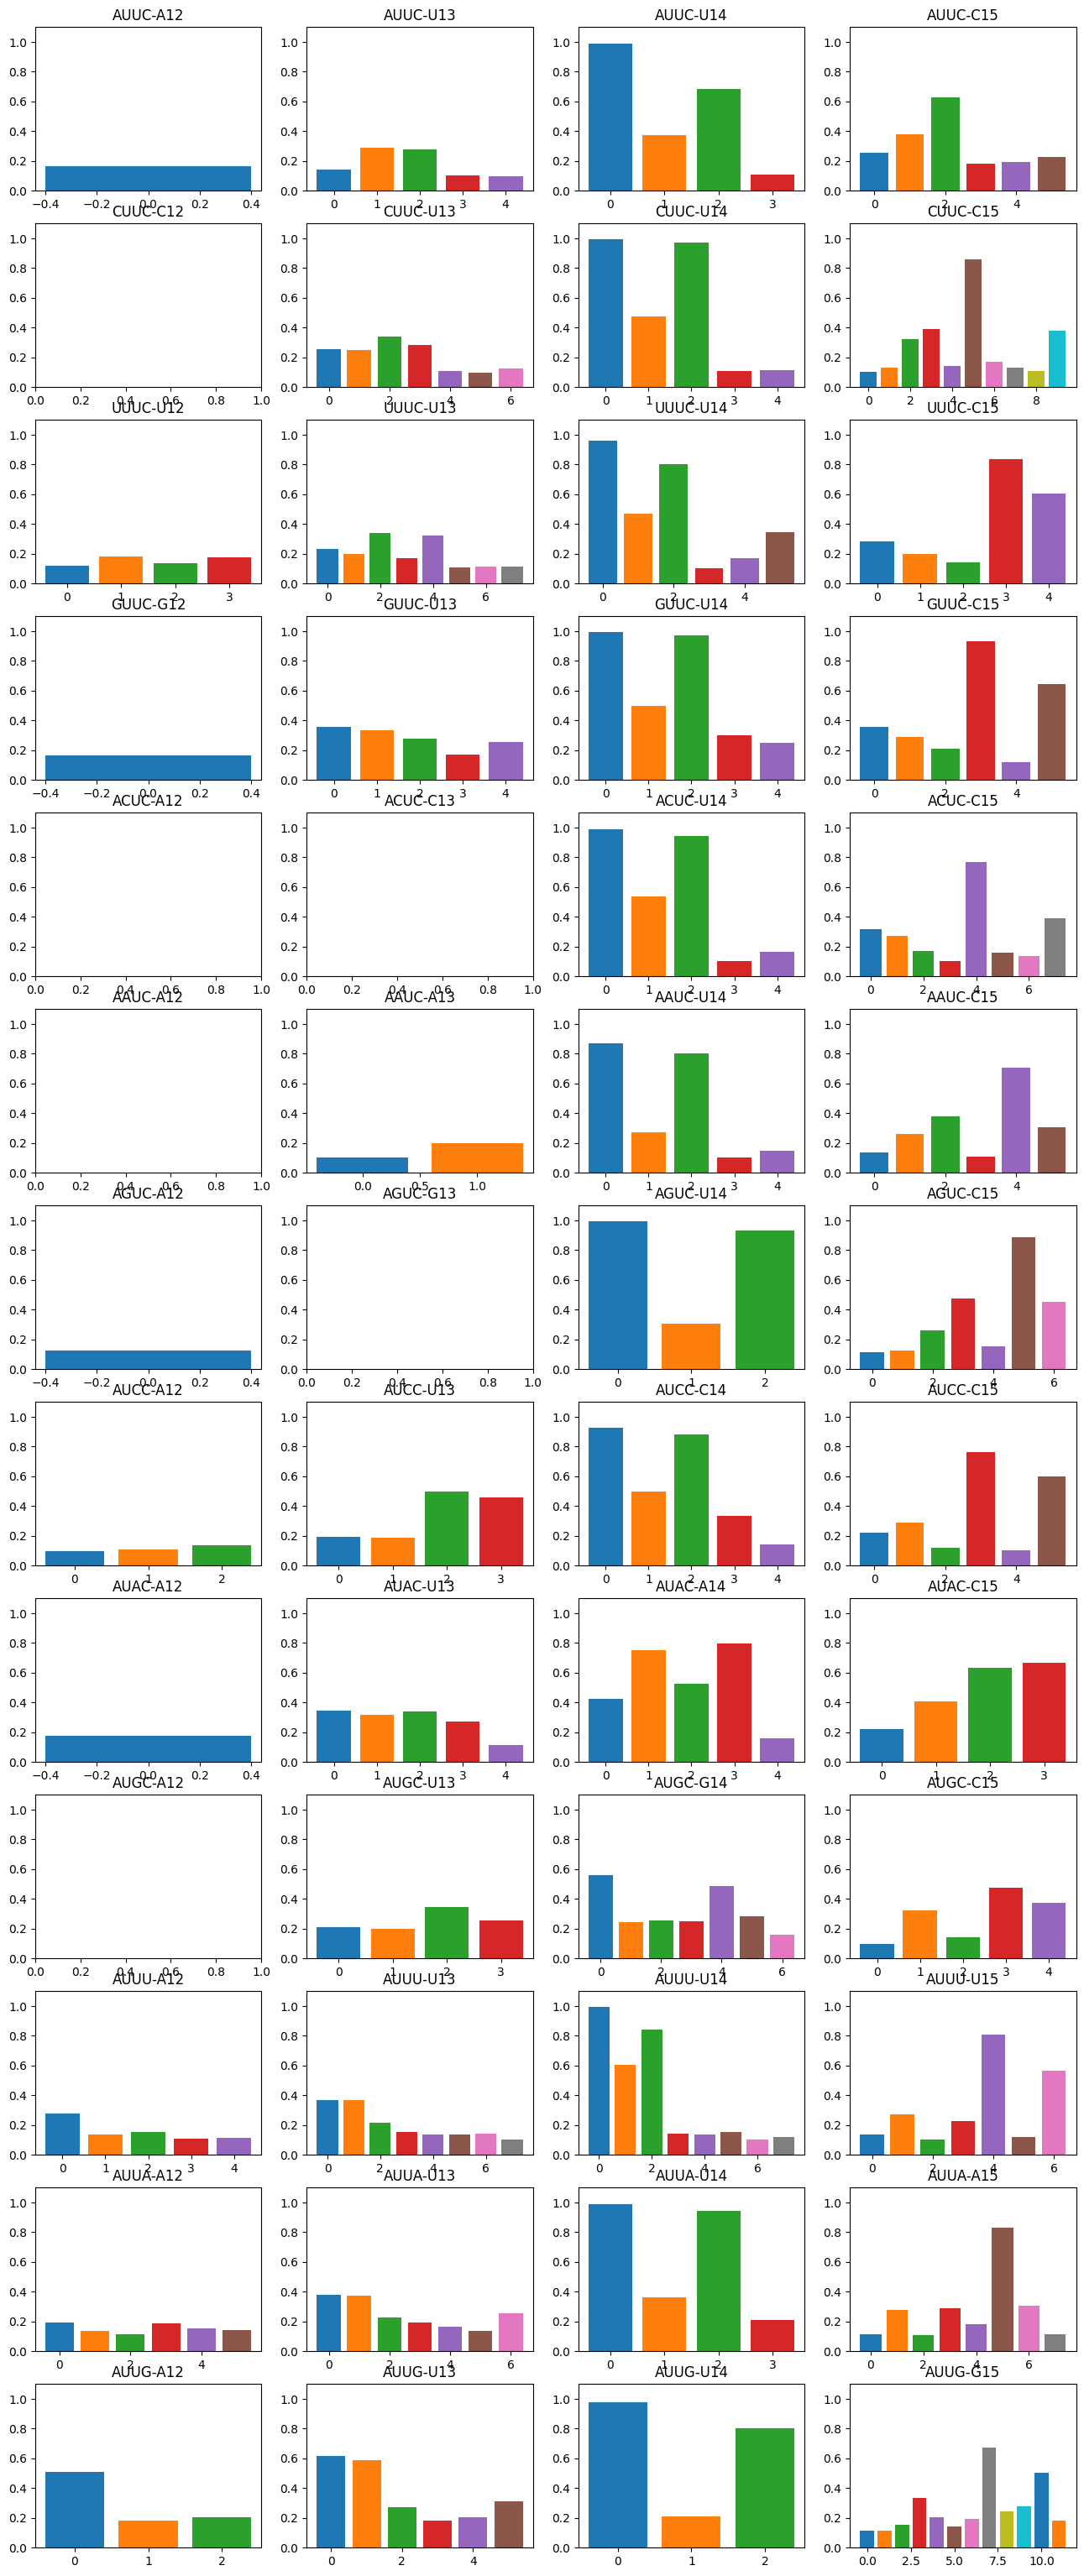

In [4]:
fig, ax = plt.subplots(len(interactions_mut), 4)
fig.set_size_inches(16, 3*len(interactions_mut))

for i_nucl, nucl in enumerate(nucls):
    for residue_index_rna in range(11, 15):
        atom_indices_rna_residue = gleap_targets[nucl].topology.select(f"resid {residue_index_rna}")
    
        dominant_pairs = []
        for atom_index_protein, atom_index_rna in np.argwhere(fractions[nucl] > 0.1):
            if atom_index_rna in atom_indices_rna_residue:
                dominant_pairs.append((atom_index_protein, atom_index_rna))
    
        xticks = []
        offset = 0
        for atom_index_protein, atom_index_rna in dominant_pairs:
            ax[i_nucl, residue_index_rna-11].bar(offset, fractions[nucl][atom_index_protein, atom_index_rna])
            xticks.append(f"{make_label_protein(gleap_targets[nucl].topology.atom(atom_index_protein+atom_index_protein_min[nucl]))}={gleap_targets[nucl].topology.atom(atom_index_rna)}")
            offset += 1
        ax[i_nucl, residue_index_rna-11].set_title(f"{nucl}-{gleap_targets[nucl].topology.residue(residue_index_rna)}")
        ax[i_nucl, residue_index_rna-11].set_ylim(0, 1.1)
        # ax[i_nucl, residue_index_rna-11].set_xticks(range(len(xticks)), xticks, rotation=-45)

In [5]:
for i_nucl, nucl in enumerate(nucls):
    fraction_sum_nucl = 0
    for residue_index_rna in range(11, 15):
        fraction_sum_rna_residue = 0
        atom_indices_rna_residue = gleap_targets[nucl].topology.select(f"resid {residue_index_rna}")

        for atom_index_protein, atom_index_rna in np.argwhere(fractions[nucl] > 0):
            if atom_index_rna in atom_indices_rna_residue:
                fraction_sum_rna_residue += fractions[nucl][atom_index_protein, atom_index_rna]

        fraction_sum_nucl += fraction_sum_rna_residue
        print(nucl, gleap_targets[nucl].topology.residue(residue_index_rna), fraction_sum_rna_residue)
    print(nucl, fraction_sum_nucl)
    print()

AUUC A12 1.0581333333333323
AUUC U13 1.8295999999999988
AUUC U14 2.6578666666666657
AUUC C15 2.6025333333333314
AUUC 8.148133333333329

CUUC C12 1.0358666666666663
CUUC U13 1.999599999999999
CUUC U14 3.0853333333333324
CUUC C15 3.121733333333333
CUUC 9.24253333333333

UUUC U12 1.2807999999999984
UUUC U13 2.2987999999999973
UUUC U14 3.4002666666666657
UUUC C15 2.666666666666665
UUUC 9.646533333333327

GUUC G12 0.8206666666666665
GUUC U13 2.3953333333333306
GUUC U14 3.2950666666666653
GUUC C15 3.1181333333333328
GUUC 9.629199999999996

ACUC A12 0.5358666666666668
ACUC C13 1.1063999999999998
ACUC U14 3.2755999999999994
ACUC C15 2.9022666666666654
ACUC 7.820133333333331

AAUC A12 0.5647999999999996
AAUC A13 1.367866666666664
AAUC U14 2.8398666666666657
AAUC C15 2.9598666666666644
AAUC 7.732399999999993

AGUC A12 0.691733333333333
AGUC G13 0.7206666666666668
AGUC U14 2.741333333333334
AGUC C15 3.148133333333332
AGUC 7.301866666666665

AUCC A12 0.8926666666666663
AUCC U13 2.224533333333331
A

AUUC
LEU324-O A12-H61 0.005840528186896902 0.34081976417742843
THR326-H U13-O2 0.15337734890807517 0.4343065693430657
THR326-OG1 U13-H3 0.14321990858303707 0.4239191465468838
THR370-H U14-O2 0.9822244794311833 0.9932622122403144
THR370-HG1 U14-O2' 0.3976637887252412 0.3419427288040427
THR370-O U14-HO2' 0.6041137633316405 0.7734418865805727
ALA369-O C15-H42 0.46419502285424075 0.28635597978663674
ARG372-H C15-OP2 0.5261554088369731 0.744806288601909
ARG372-HH21 C15-OP1 0.06500761808024377 0.33015160022459294

LEU324-O A12-H61 0.005840528186896902 0.34081976417742843
THR326-H U13-O2 0.15337734890807517 0.4343065693430657
THR326-OG1 U13-H3 0.14321990858303707 0.4239191465468838
THR370-H U14-O2 0.9822244794311833 0.9932622122403144
THR370-HG1 U14-O2' 0.3976637887252412 0.3419427288040427
THR370-O U14-HO2' 0.6041137633316405 0.7734418865805727
ALA369-O C15-H42 0.46419502285424075 0.28635597978663674
ARG372-H C15-OP2 0.5261554088369731 0.744806288601909
ARG372-HH21 C15-OP1 0.0650076180802437

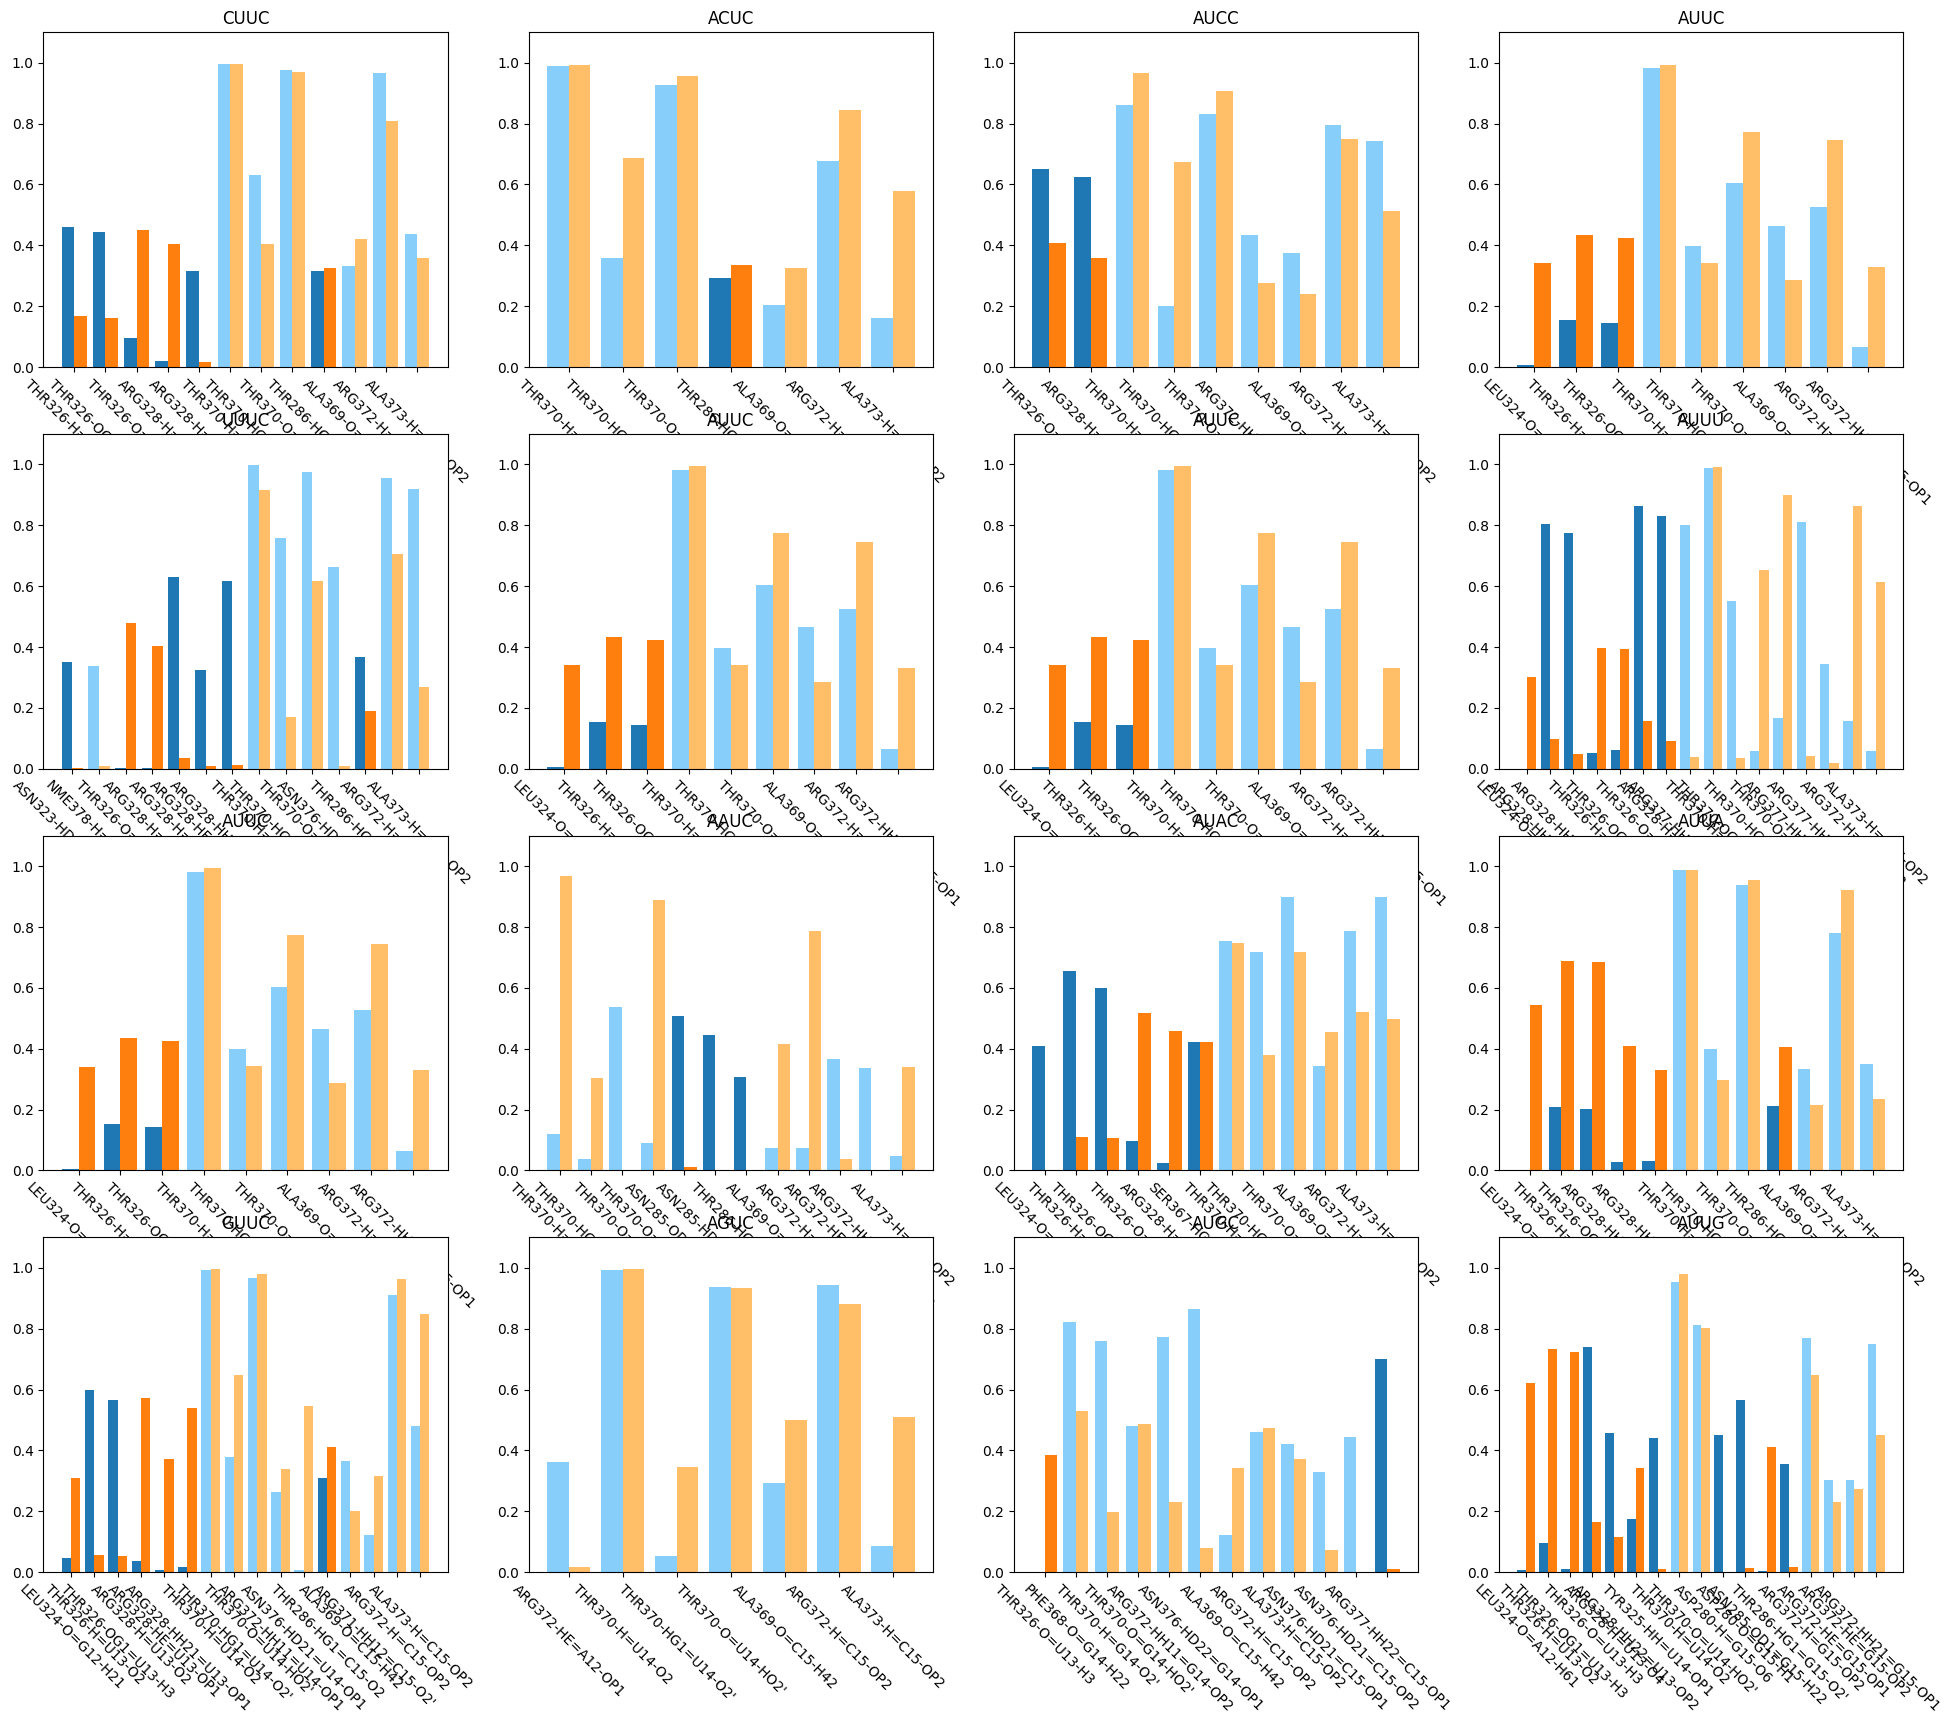

In [6]:
import pickle


atom_indices_protein_rgion = {
    "rrm": list(gleap_targets["AUUC"].topology.select("resid  24 to 116")),
    "rgg": list(gleap_targets["AUUC"].topology.select("resid 117 to 125")),
}

colors = [
    {
        "rrm": "tab:blue",
        "rgg": "lightskyblue",
    },
    {
        "rrm": "tab:orange",
        "rgg": "#FFBE67",
    },
]

ax_positions = {
    "AUUC": [(2,0), (1,1), (1,2), (0,3)],
    "CUUC": [(0,0)],
    "UUUC": [(1,0)],
    "GUUC": [(3,0)],
    "ACUC": [(0,1)],
    "AAUC": [(2,1)],
    "AGUC": [(3,1)],
    "AUCC": [(0,2)],
    "AUAC": [(2,2)],
    "AUGC": [(3,2)],
    "AUUU": [(1,3)],
    "AUUA": [(2,3)],
    "AUUG": [(3,3)],
    "free": [(0,4)],
}

fig, ax = plt.subplots(4, 4)
fig.set_size_inches(24, 20)

for i_nucl, nucl in enumerate(nucls):
    print(nucl)
    metastabled_trajs_concat = pickle.load(open(f"./pickle-cache/pca_tetranucl_all_mut/metastabled_trajs_concat_{nucl}_2.pickle", "rb")).reshape(5, 15000)[:, ::10]
    fractions0 = interactions_mut[nucl].transpose(1, 2, 0, 3)[:, :, metastabled_trajs_concat==0].mean(axis=2)
    fractions1 = interactions_mut[nucl].transpose(1, 2, 0, 3)[:, :, metastabled_trajs_concat==1].mean(axis=2)

    dominant_pairs = []
    for residue_index_rna in range(11, 15):
        atom_indices_rna_residue = gleap_targets[nucl].topology.select(f"resid {residue_index_rna}")
        for atom_index_protein, atom_index_rna in np.argwhere((fractions0 > 0.3) | (fractions1 > 0.3)):
            if atom_index_rna in atom_indices_rna_residue:
                dominant_pairs.append((atom_index_protein, atom_index_rna))

    for ax_position in ax_positions[nucl]:
        xticks = []
        offset = 0
        for atom_index_protein, atom_index_rna in dominant_pairs:
            atom_protein = gleap_targets[nucl].topology.atom(atom_index_protein)
            atom_rna     = gleap_targets[nucl].topology.atom(atom_index_rna)

            region = "rrm"
            if atom_index_protein+atom_index_protein_min[nucl] in atom_indices_protein_rgion["rgg"]:
                region = "rgg"

            ax[ax_position].bar(offset-0.2, fractions0[atom_index_protein, atom_index_rna], width=0.4, color=colors[0][region])
            ax[ax_position].bar(offset+0.2, fractions1[atom_index_protein, atom_index_rna], width=0.4, color=colors[1][region])
            xticks.append(f"{make_label_protein(gleap_targets[nucl].topology.atom(atom_index_protein+atom_index_protein_min[nucl]))}={gleap_targets[nucl].topology.atom(atom_index_rna)}")
            print(make_label_protein(gleap_targets[nucl].topology.atom(atom_index_protein+atom_index_protein_min[nucl])), gleap_targets[nucl].topology.atom(atom_index_rna), fractions0[atom_index_protein, atom_index_rna], fractions1[atom_index_protein, atom_index_rna])
            offset += 1
        ax[ax_position].set_title(nucl)
        ax[ax_position].set_ylim(0, 1.1)
        ax[ax_position].set_xticks(range(len(xticks)), xticks, rotation=-45)
        print()
    print("--------------------")
    print()

AUUC
LEU324-O A12-H61 0.005840528186896902 0.34081976417742843
THR326-OG1 A12-H62 0.0012696800406297613 0.13279056709713644
THR326-H U13-O2 0.15337734890807517 0.4343065693430657
THR326-OG1 U13-H3 0.14321990858303707 0.4239191465468838
THR326-O U13-H3 0.1706449974606399 0.029477821448624368
ARG328-H U13-O4 0.14931437277805992 0.005334081976417743
ARG328-H U13-O2 0.019553072625698324 0.14626614261650758
THR370-H U14-O2 0.9822244794311833 0.9932622122403144
THR286-HG1 C15-O2 0.21152869476891822 0.29927007299270075
ALA369-O C15-H42 0.46419502285424075 0.28635597978663674

LEU324-O A12-H61 0.005840528186896902 0.34081976417742843
THR326-OG1 A12-H62 0.0012696800406297613 0.13279056709713644
THR326-H U13-O2 0.15337734890807517 0.4343065693430657
THR326-OG1 U13-H3 0.14321990858303707 0.4239191465468838
THR326-O U13-H3 0.1706449974606399 0.029477821448624368
ARG328-H U13-O4 0.14931437277805992 0.005334081976417743
ARG328-H U13-O2 0.019553072625698324 0.14626614261650758
THR370-H U14-O2 0.98222

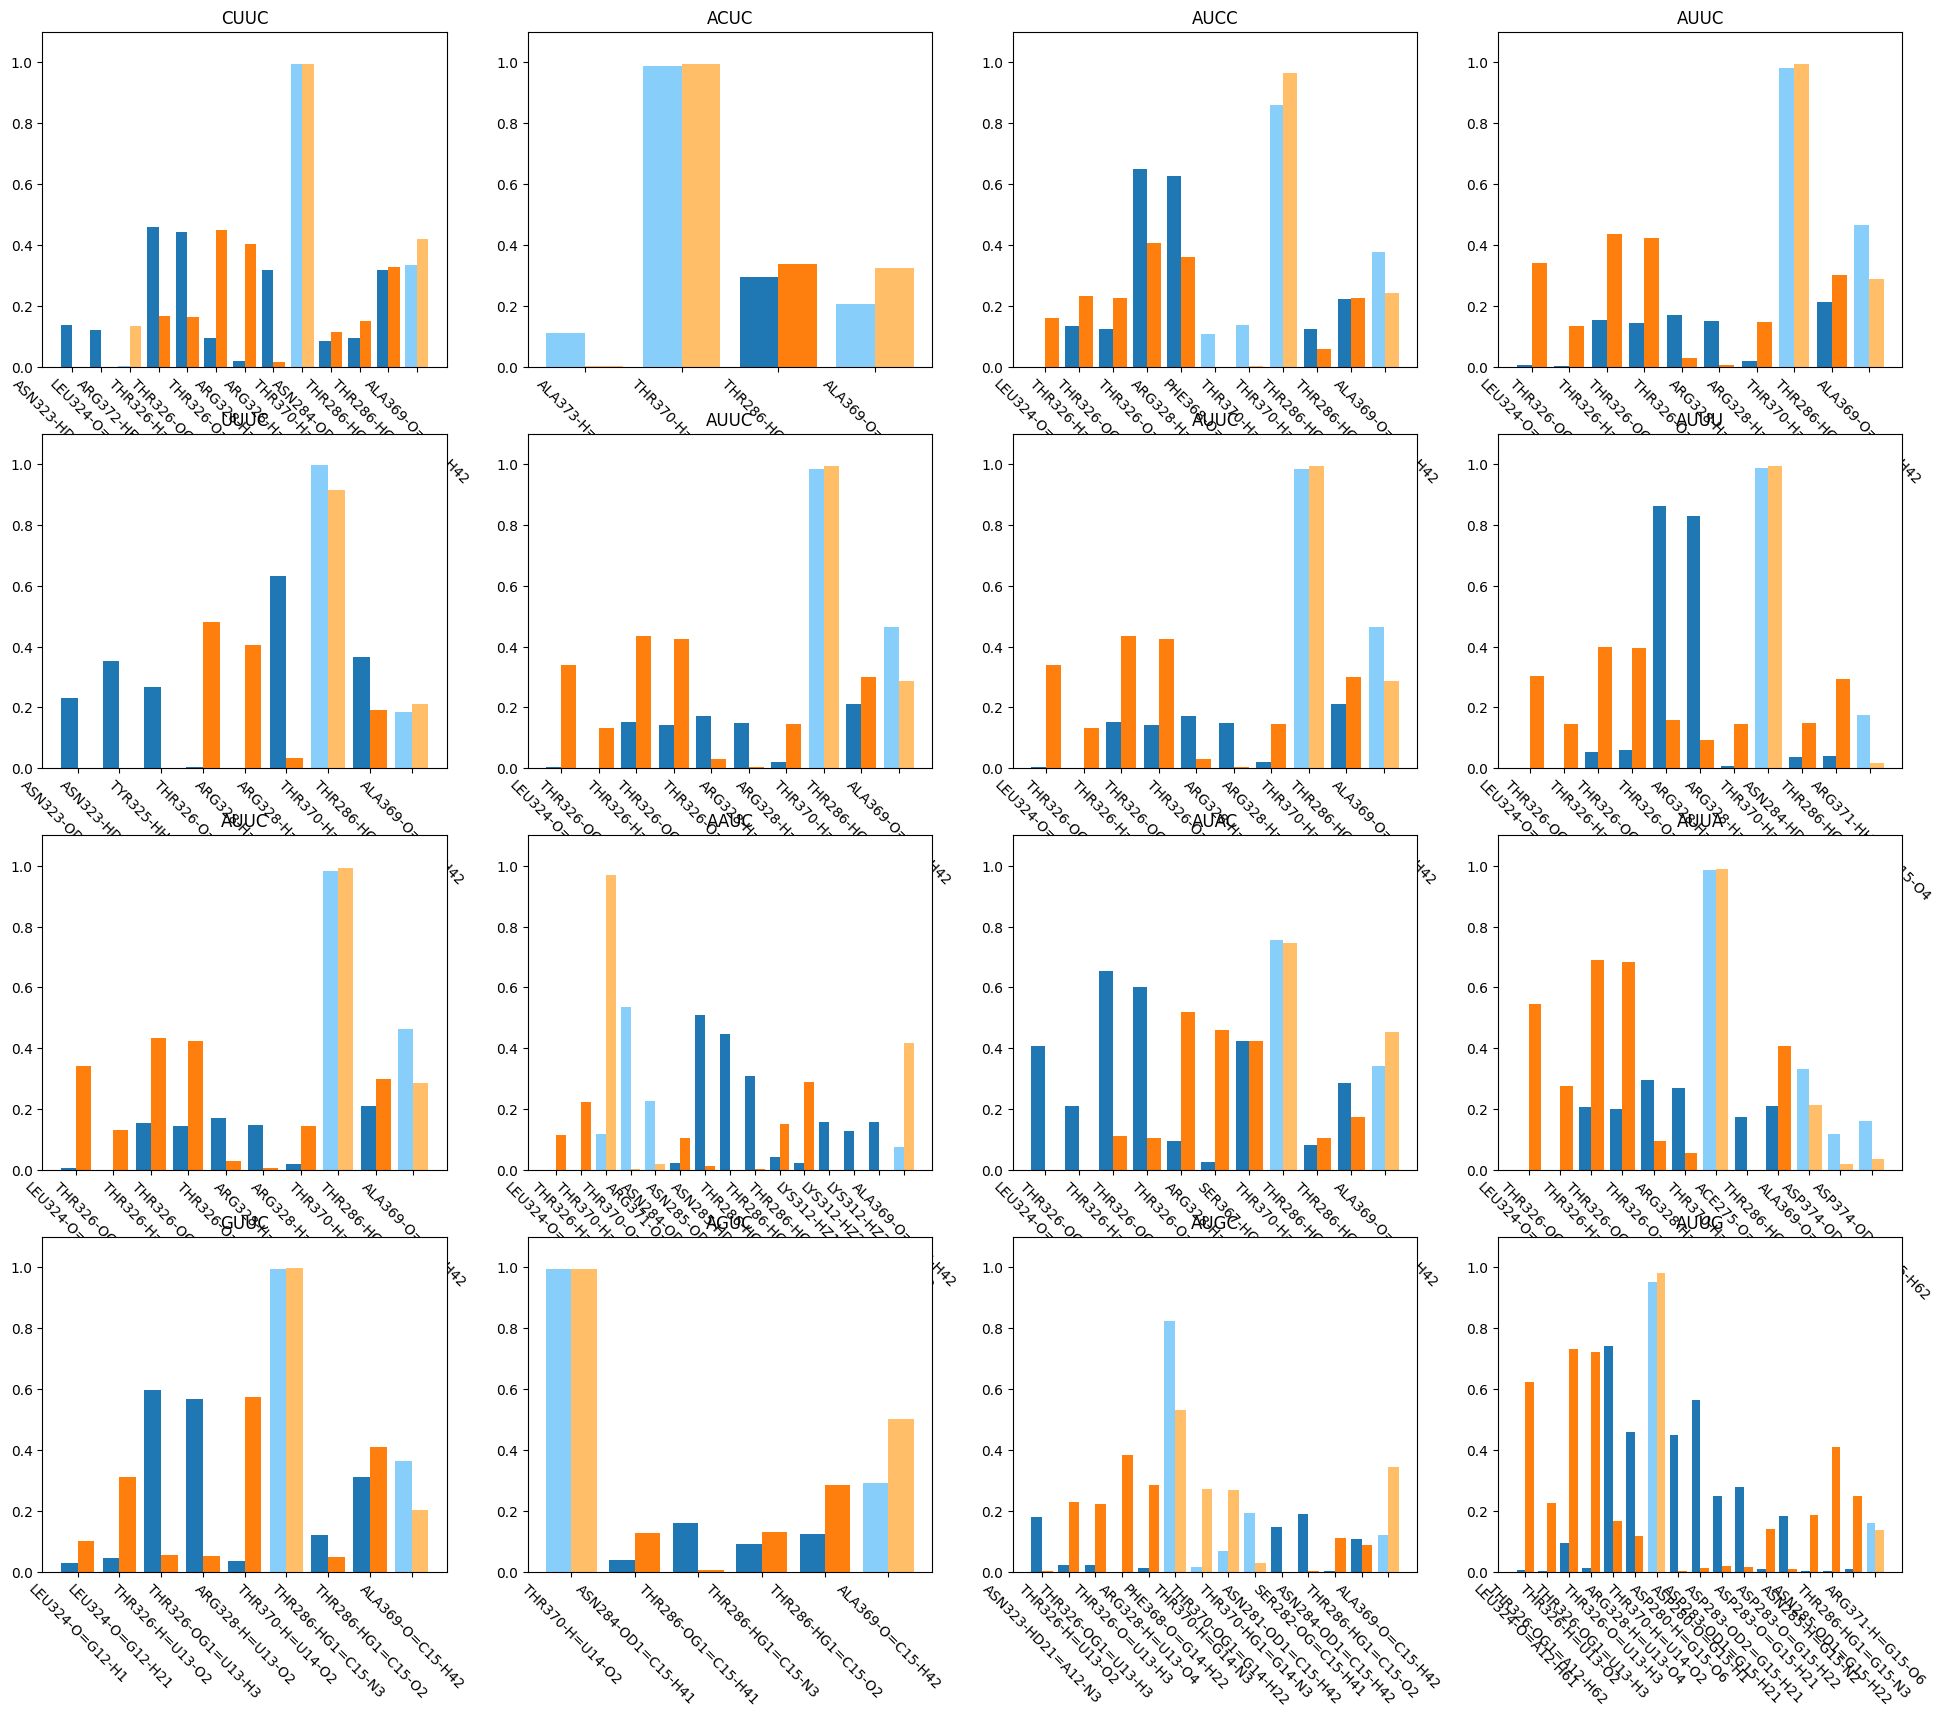

In [7]:
fig, ax = plt.subplots(4, 4)
fig.set_size_inches(24, 20)

for i_nucl, nucl in enumerate(nucls):
    print(nucl)
    metastabled_trajs_concat = pickle.load(open(f"./pickle-cache/pca_tetranucl_all_mut/metastabled_trajs_concat_{nucl}_2.pickle", "rb")).reshape(5, 15000)[:, ::10]
    fractions0 = interactions_mut[nucl].transpose(1, 2, 0, 3)[:, :, metastabled_trajs_concat==0].mean(axis=2)
    fractions1 = interactions_mut[nucl].transpose(1, 2, 0, 3)[:, :, metastabled_trajs_concat==1].mean(axis=2)

    dominant_pairs = []
    for residue_index_rna in range(11, 15):
        atom_indices_rna_residue = []
        for atom_index_rna_residue in gleap_targets[nucl].topology.select(f"resid {residue_index_rna}"):
            if "'" in gleap_targets[nucl].topology.atom(atom_index_rna_residue).name:
                continue
            if gleap_targets[nucl].topology.atom(atom_index_rna_residue).name in ["P", "OP1", "OP2"]:
                continue
            atom_indices_rna_residue.append(atom_index_rna_residue)
        
        for atom_index_protein, atom_index_rna in np.argwhere((fractions0 > 0.1) | (fractions1 > 0.1)):
            if atom_index_rna in atom_indices_rna_residue:
                dominant_pairs.append((atom_index_protein, atom_index_rna))

    for ax_position in ax_positions[nucl]:
        xticks = []
        offset = 0
        for atom_index_protein, atom_index_rna in dominant_pairs:
            atom_protein = gleap_targets[nucl].topology.atom(atom_index_protein)
            atom_rna     = gleap_targets[nucl].topology.atom(atom_index_rna)

            region = "rrm"
            if atom_index_protein+atom_index_protein_min[nucl] in atom_indices_protein_rgion["rgg"]:
                region = "rgg"

            ax[ax_position].bar(offset-0.2, fractions0[atom_index_protein, atom_index_rna], width=0.4, color=colors[0][region])
            ax[ax_position].bar(offset+0.2, fractions1[atom_index_protein, atom_index_rna], width=0.4, color=colors[1][region])
            xticks.append(f"{make_label_protein(gleap_targets[nucl].topology.atom(atom_index_protein+atom_index_protein_min[nucl]))}={gleap_targets[nucl].topology.atom(atom_index_rna)}")
            print(make_label_protein(gleap_targets[nucl].topology.atom(atom_index_protein+atom_index_protein_min[nucl])), gleap_targets[nucl].topology.atom(atom_index_rna), fractions0[atom_index_protein, atom_index_rna], fractions1[atom_index_protein, atom_index_rna])
            offset += 1
        ax[ax_position].set_title(nucl)
        ax[ax_position].set_ylim(0, 1.1)
        ax[ax_position].set_xticks(range(len(xticks)), xticks, rotation=-45)
        print()
    print("--------------------")
    print()

AUUC
A12-H61 0.03453529710512951 0.36299831555306006
A12-H62 0.0025393600812595226 0.13924761370016844
U13-O4 0.1632808532249873 0.07495788882650196
U13-H3 0.3164042661249365 0.527793374508703
U13-O2 0.21533773489080751 0.6027512633352049
U14-O2 0.9824784154393092 0.9932622122403144
C15-H41 0.10589131538852209 0.07215047725996632
C15-H42 0.531742001015744 0.3250982594048287
C15-N3 0.10335195530726257 0.05783267827063447
C15-O2 0.2473336719146775 0.3329590117911286

A12-H61 0.03453529710512951 0.36299831555306006
A12-H62 0.0025393600812595226 0.13924761370016844
U13-O4 0.1632808532249873 0.07495788882650196
U13-H3 0.3164042661249365 0.527793374508703
U13-O2 0.21533773489080751 0.6027512633352049
U14-O2 0.9824784154393092 0.9932622122403144
C15-H41 0.10589131538852209 0.07215047725996632
C15-H42 0.531742001015744 0.3250982594048287
C15-N3 0.10335195530726257 0.05783267827063447
C15-O2 0.2473336719146775 0.3329590117911286

A12-H61 0.03453529710512951 0.36299831555306006
A12-H62 0.0025393

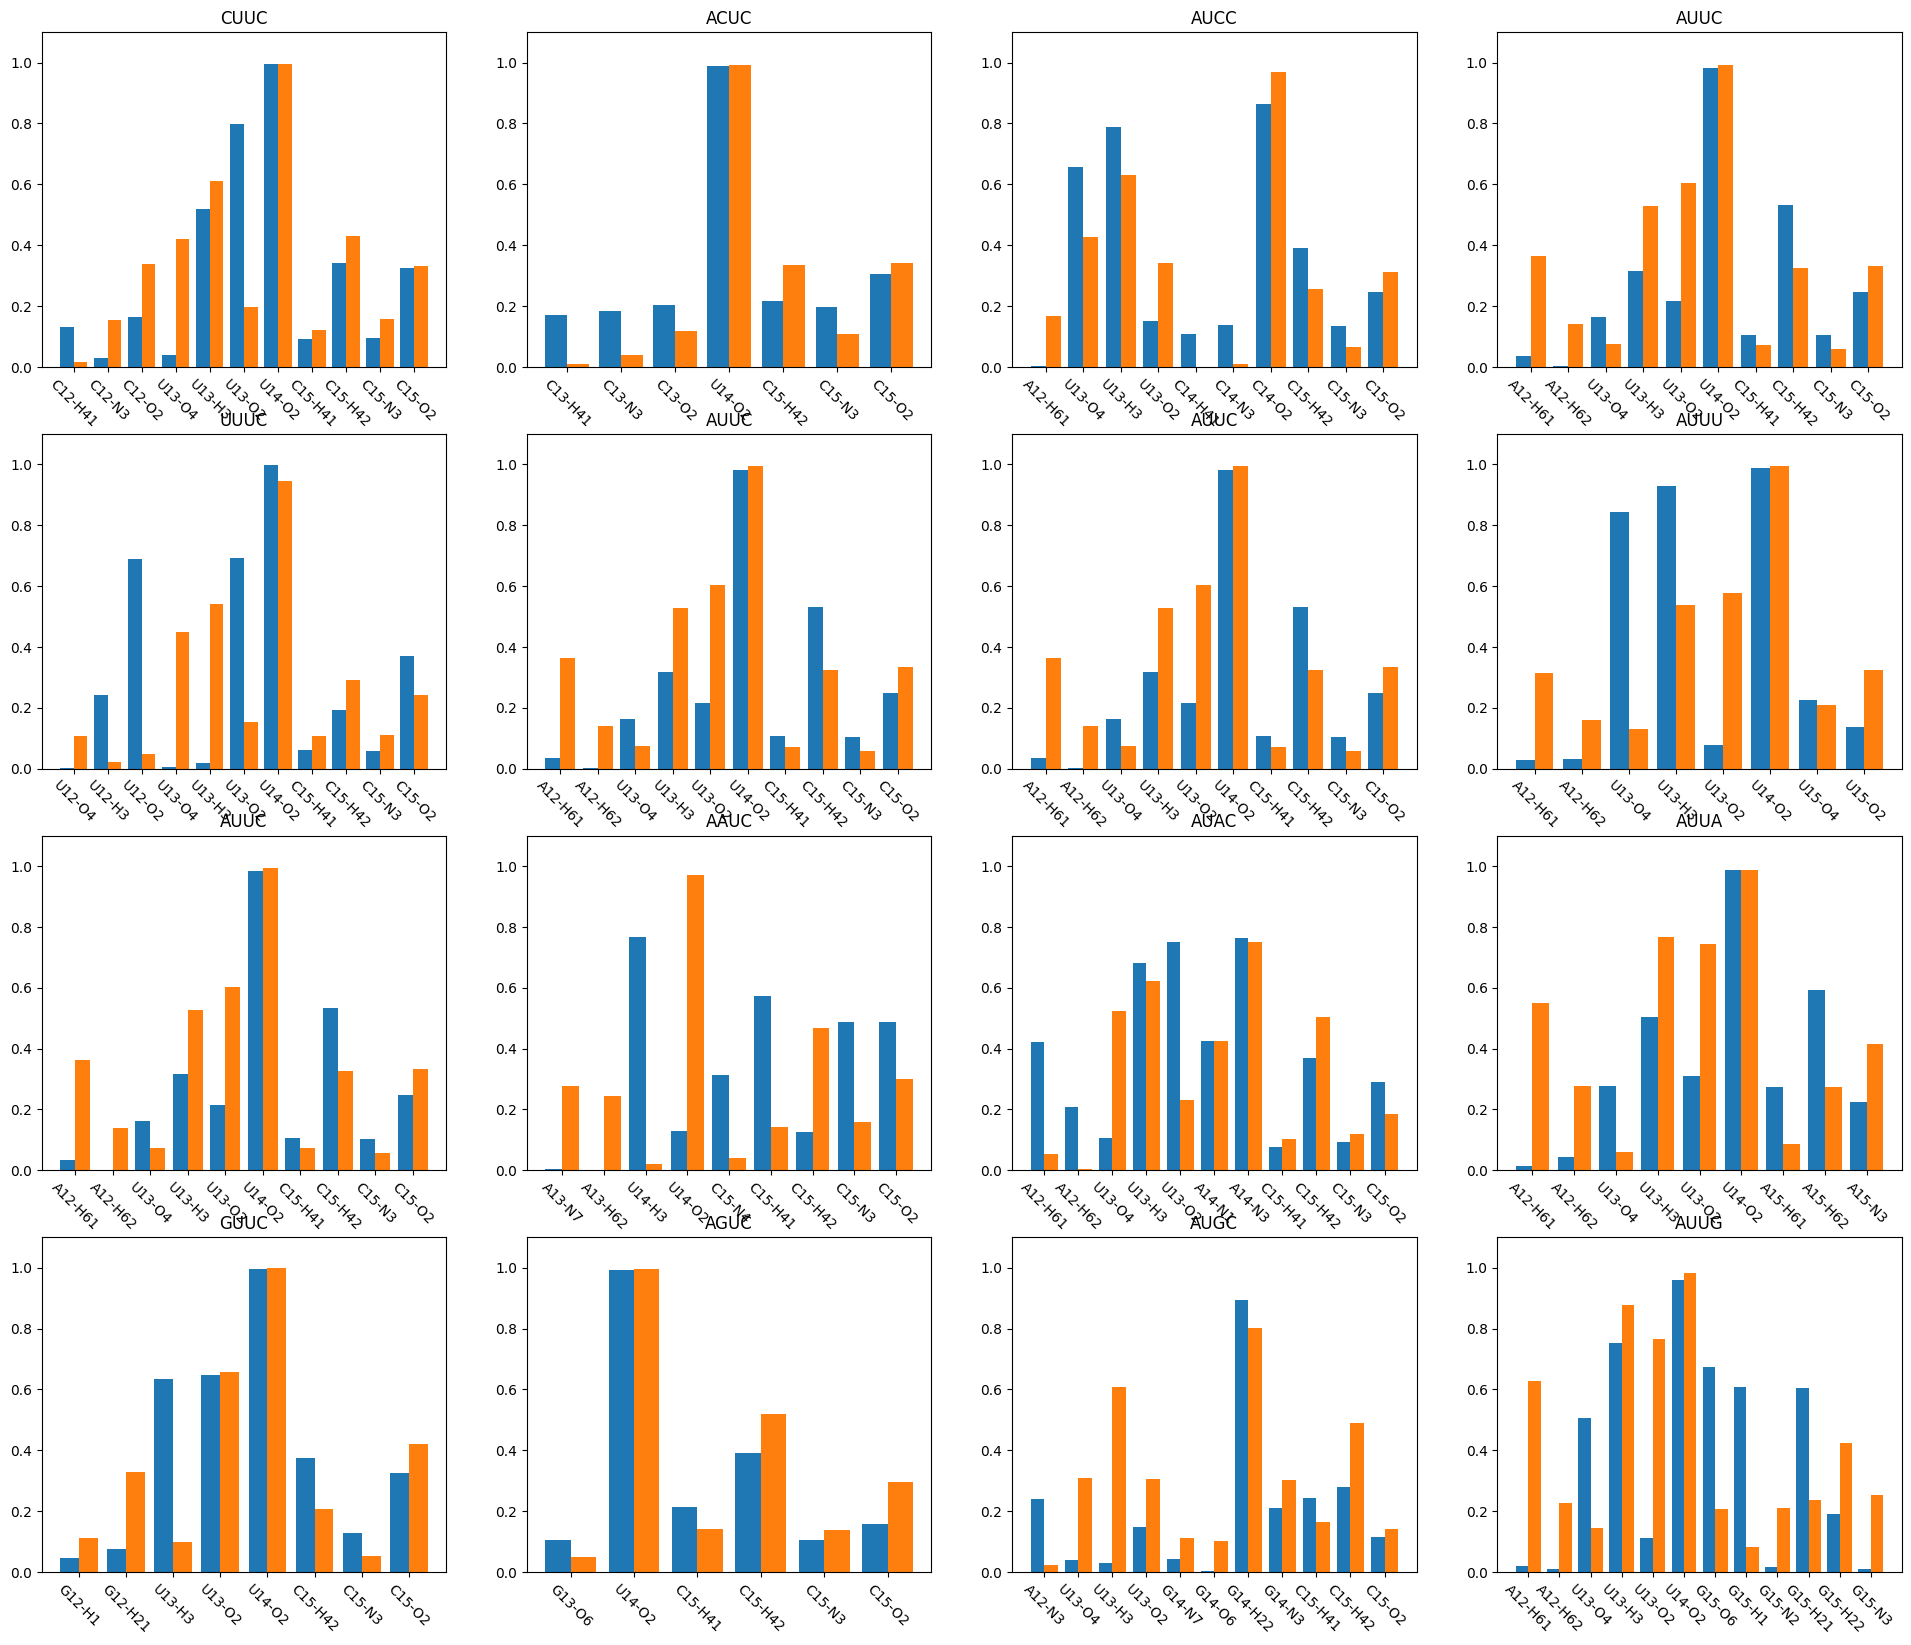

In [8]:
fig, ax = plt.subplots(4, 4)
fig.set_size_inches(24, 20)

for i_nucl, nucl in enumerate(nucls):
    print(nucl)
    metastabled_trajs_concat = pickle.load(open(f"./pickle-cache/pca_tetranucl_all_mut/metastabled_trajs_concat_{nucl}_2.pickle", "rb")).reshape(5, 15000)[:, ::10]
    fractions0 = interactions_mut[nucl].transpose(1, 2, 0, 3)[:, :, metastabled_trajs_concat==0].sum(axis=0).astype(bool).astype(np.int32).mean(axis=1)
    fractions1 = interactions_mut[nucl].transpose(1, 2, 0, 3)[:, :, metastabled_trajs_concat==1].sum(axis=0).astype(bool).astype(np.int32).mean(axis=1)

    dominant_pairs = []
    for residue_index_rna in range(11, 15):
        atom_indices_rna_residue = []
        for atom_index_rna_residue in gleap_targets[nucl].topology.select(f"resid {residue_index_rna}"):
            if "'" in gleap_targets[nucl].topology.atom(atom_index_rna_residue).name:
                continue
            if gleap_targets[nucl].topology.atom(atom_index_rna_residue).name in ["P", "OP1", "OP2"]:
                continue
            atom_indices_rna_residue.append(atom_index_rna_residue)
        
        for atom_index_rna in np.where((fractions0 > 0.1) | (fractions1 > 0.1))[0]:
            # dominant_pairs.append(atom_index_rna)
            if atom_index_rna in atom_indices_rna_residue:
                dominant_pairs.append(atom_index_rna)

    for ax_position in ax_positions[nucl]:
        xticks = []
        offset = 0
        for atom_index_rna in dominant_pairs:
            atom_rna     = gleap_targets[nucl].topology.atom(atom_index_rna)

            ax[ax_position].bar(offset-0.2, fractions0[atom_index_rna], width=0.4, color=colors[0]["rrm"])
            ax[ax_position].bar(offset+0.2, fractions1[atom_index_rna], width=0.4, color=colors[1]["rrm"])
            xticks.append(gleap_targets[nucl].topology.atom(atom_index_rna))
            print(gleap_targets[nucl].topology.atom(atom_index_rna), fractions0[atom_index_rna], fractions1[atom_index_rna])
            offset += 1
        ax[ax_position].set_title(nucl)
        ax[ax_position].set_ylim(0, 1.1)
        ax[ax_position].set_xticks(range(len(xticks)), xticks, rotation=-45)
        print()
    print("--------------------")
    print()

AUUC 11.076933333333333
A12-H61 0.19053333333333333
U13-O4 0.12133333333333333
U13-H3 0.4168
U13-O2 0.3993333333333333
U14-O2 0.9876
C15-H42 0.4336
C15-O2 0.288

A12-H61 0.19053333333333333
U13-O4 0.12133333333333333
U13-H3 0.4168
U13-O2 0.3993333333333333
U14-O2 0.9876
C15-H42 0.4336
C15-O2 0.288

A12-H61 0.19053333333333333
U13-O4 0.12133333333333333
U13-H3 0.4168
U13-O2 0.3993333333333333
U14-O2 0.9876
C15-H42 0.4336
C15-O2 0.288

A12-H61 0.19053333333333333
U13-O4 0.12133333333333333
U13-H3 0.4168
U13-O2 0.3993333333333333
U14-O2 0.9876
C15-H42 0.4336
C15-O2 0.288

--------------------

CUUC 11.872133333333332
C12-N3 0.116
C12-O2 0.2830666666666667
U13-O4 0.30133333333333334
U13-H3 0.5818666666666666
U13-O2 0.3837333333333333
U14-O2 0.9952
C15-H41 0.11226666666666667
C15-H42 0.4032
C15-N3 0.138
C15-O2 0.3296

--------------------

UUUC 11.462666666666667
U12-H3 0.13426666666666667
U12-O2 0.3761333333333333
U13-O4 0.22013333333333332
U13-H3 0.27226666666666666
U13-O2 0.4302666666666

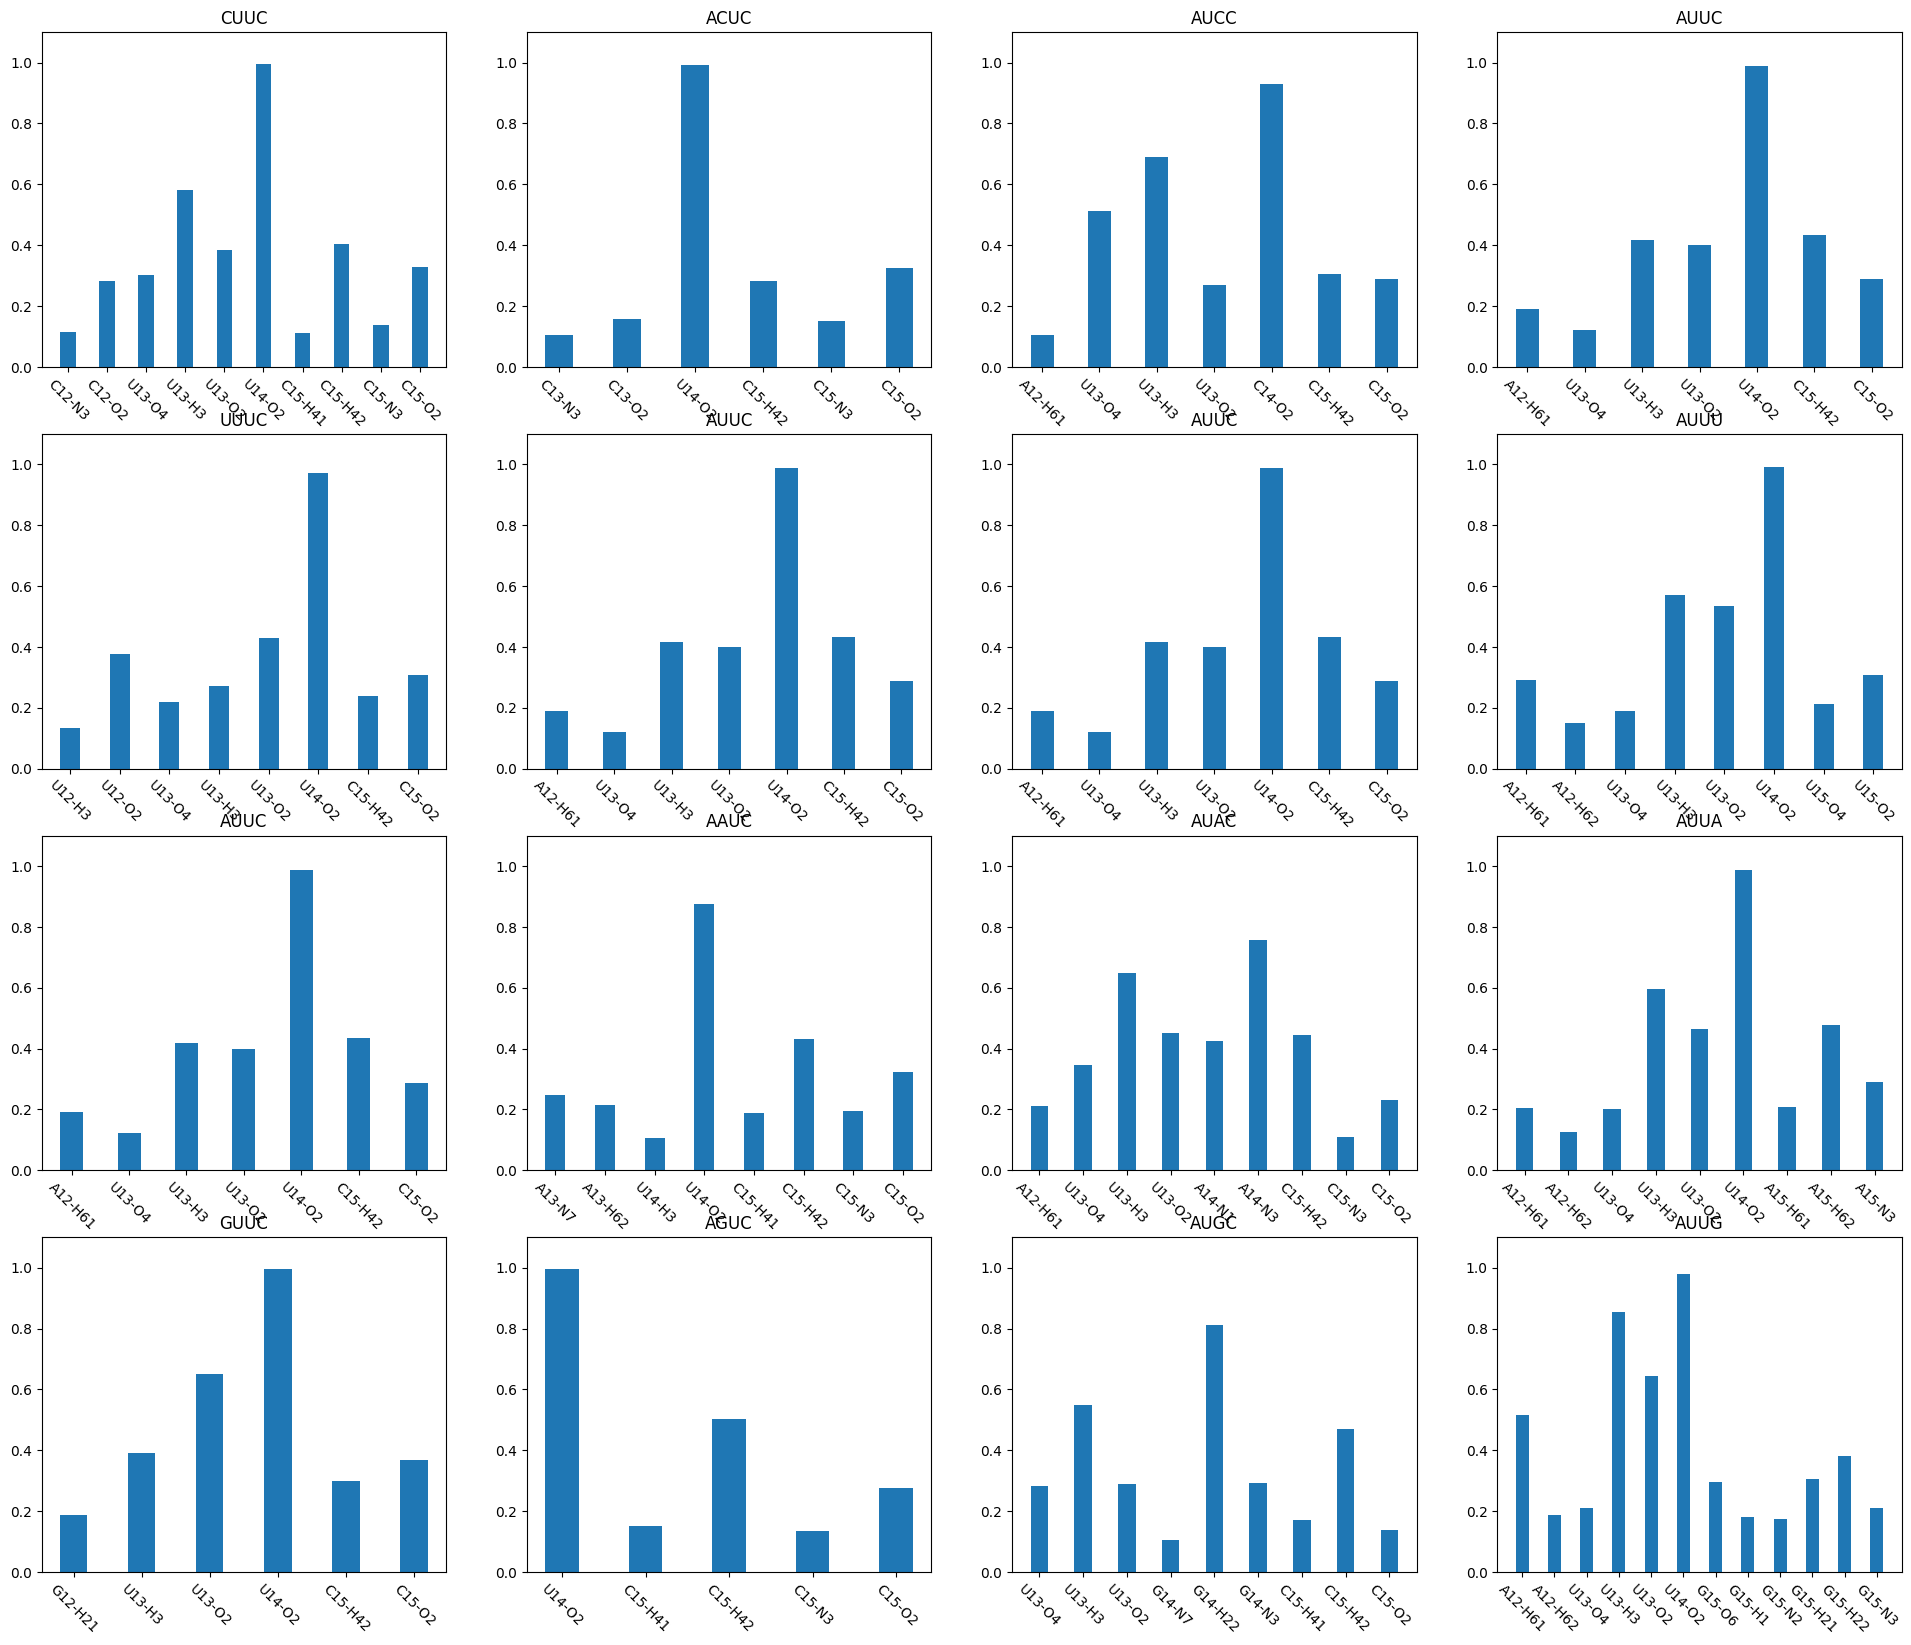

In [9]:
fig, ax = plt.subplots(4, 4)
fig.set_size_inches(24, 20)

for i_nucl, nucl in enumerate(nucls):
    fractions = interactions_mut[nucl].sum(axis=1).astype(bool).astype(np.int32).transpose(0, 2, 1).reshape(7500, -1).mean(axis=0)
    print(nucl, fractions.sum())

    dominant_pairs = []
    for residue_index_rna in range(11, 15):
        atom_indices_rna_residue = []
        for atom_index_rna_residue in gleap_targets[nucl].topology.select(f"resid {residue_index_rna}"):
            if "'" in gleap_targets[nucl].topology.atom(atom_index_rna_residue).name:
                continue
            if gleap_targets[nucl].topology.atom(atom_index_rna_residue).name in ["P", "OP1", "OP2"]:
                continue
            atom_indices_rna_residue.append(atom_index_rna_residue)
        
        for atom_index_rna in np.where(0.1 < fractions)[0]:
            # dominant_pairs.append(atom_index_rna)
            if atom_index_rna in atom_indices_rna_residue:
                dominant_pairs.append(atom_index_rna)

    for ax_position in ax_positions[nucl]:
        xticks = []
        offset = 0
        for atom_index_rna in dominant_pairs:
            atom_rna     = gleap_targets[nucl].topology.atom(atom_index_rna)

            ax[ax_position].bar(offset, fractions[atom_index_rna], width=0.4, color=colors[0]["rrm"])
            xticks.append(gleap_targets[nucl].topology.atom(atom_index_rna))
            print(gleap_targets[nucl].topology.atom(atom_index_rna), fractions[atom_index_rna])
            offset += 1
        ax[ax_position].set_title(nucl)
        ax[ax_position].set_ylim(0, 1.1)
        ax[ax_position].set_xticks(range(len(xticks)), xticks, rotation=-45)
        print()
    print("--------------------")
    print()